# 06 – Baseline clustering

**Goal:** the first working pipeline: 6 indicators per cell → transform → standardise → k-means → profile → map.
This is the **baseline** that everything later (more layers, learned embeddings) is compared against.

- **Input:** `data/processed/cells.gpkg` + `ind_buildings.csv`, `ind_land_cover.csv`, `ind_poi.csv`, `ind_streets.csv`
- **Output:** `data/processed/clusters_baseline.csv` (cluster label per cell for every k from 4 to 12)

**The 6 indicators (one per layer):**

| layer | indicator | transform |
|---|---|---|
| people | `pop` – residents per cell (= per ha) | log(1 + x), dorm cell capped |
| ground surface | `imp_share` – share of sealed surface | none (already 0–1) |
| buildings | `bld_height` – mean building height (m) | none |
| greenery | `can_cover` – tree canopy share | none (already 0–1) |
| function | `poi_count` – number of POI | log(1 + x) |
| streets | `str_intersections` – number of intersections | log(1 + x) |

Why these: in 05/02/03 we saw that building coverage and FAR repeat imperviousness (Spearman 0.8), and NDVI is almost its mirror image (−0.91).
Height and canopy add information imperviousness doesn't have (vertical form, trees vs grass).

**Cells:** only cells inside the building data extent (settlement Ljubljana, option A), minus water.

## 1. Setup

In [1]:
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score, davies_bouldin_score, silhouette_score
from sklearn.preprocessing import StandardScaler

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
PROCESSED = ROOT / "data" / "processed"
FIGURES = ROOT / "figures"

SEED = 0
K_RANGE = range(4, 13)
K = 6                    # chosen number of clusters, see section 5
WATER_THRESHOLD = 0.5      # cells with more than half negative NDVI are water
DORM_CELL = "SIHM100_4603_1014"

FEATURES = ["pop", "imp_share", "bld_height", "can_cover", "poi_count", "str_intersections"]
LOG_FEATURES = ["pop", "poi_count", "str_intersections"]

# Categorical colours (fixed order, from the dataviz reference palette); max 8 clusters
CLUSTER_COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]

## 2. Load and join all indicators

In [2]:
cells = gpd.read_file(PROCESSED / "cells.gpkg", layer="cells")
data = cells.set_index("cell_id").drop(columns="geometry")
for name in ["buildings", "land_cover", "poi", "streets"]:
    data = data.join(pd.read_csv(PROCESSED / f"ind_{name}.csv", index_col="cell_id"))
print(f"{len(data):,} cells, {data.shape[1]} columns")

C:\Users\Maks\miniforge3\envs\urban\Lib\site-packages\pyogrio\core.py:34: RuntimeWarning: Could not detect GDAL data files. Set GDAL_DATA environment variable to the correct path.
  _init_gdal_data()


27,505 cells, 34 columns


## 3. Choose the cells
1. Only cells with building data (`bld_in_data`), otherwise `bld_height` is unknown.
2. Remove water cells (mostly negative NDVI), because a river is not an urban type.

In [3]:
in_extent = data["bld_in_data"]
water = data["ndvi_neg_share"] > WATER_THRESHOLD
use = in_extent & ~water

print(f"In building extent: {in_extent.sum():,}")
print(f"Water cells removed: {(in_extent & water).sum()}")
print(f"Cells for clustering: {use.sum():,} ({data.loc[use, 'pop'].sum():,.0f} of {data['pop'].sum():,.0f} residents)")

X_raw = data.loc[use, FEATURES].copy()
assert X_raw.notna().all().all(), X_raw.isna().sum()
X_raw.describe().round(2).T

In building extent: 27,483
Water cells removed: 18
Cells for clustering: 27,465 (300,426 of 300,443 residents)


,count,mean,std,min,25%,50%,75%,max
pop,27465.0,10.94,43.23,0.0,0.00,0.00,0.00,2843.0
imp_share,27465.0,0.13,0.24,0.0,0.00,0.00,0.15,1.0
bld_height,27465.0,3.21,5.28,0.0,0.00,0.00,6.69,77.0
can_cover,27465.0,0.45,0.40,0.0,0.06,0.31,0.92,1.0
poi_count,27465.0,0.12,0.75,0.0,0.00,0.00,0.00,39.0
str_intersections,27465.0,0.17,0.59,0.0,0.00,0.00,0.00,13.0


## 4. Transform and standardise
**Dorm cell:** 2,843 residents, about 10× any other cell. We cap it at the second-highest value, so it stays "very dense" but doesn't pull a cluster of its own.

**Log:** residents, POI and intersections are counts where most cells are 0 and a few are very high. Without the log, these few cells set the scale and all ordinary cells get squeezed together.
log(1 + x) keeps 0 at 0 and makes the step from 0 to 10 matter more than from 100 to 110.

**Standardise (z-score):** every indicator gets mean 0 and std 1, so k-means weighs them equally. Without this, the indicator with the biggest numbers would decide the clusters.

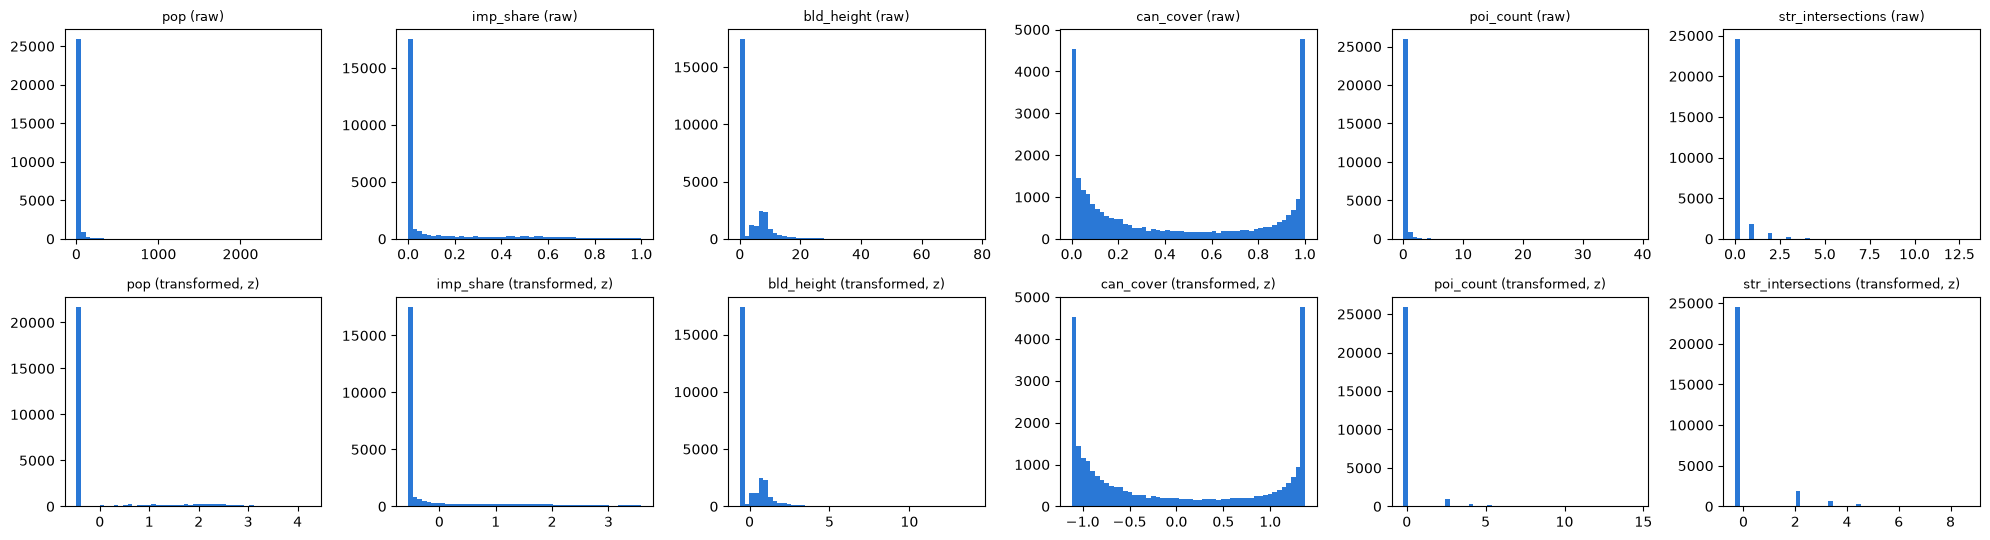

In [4]:
X = X_raw.copy()
X.loc[DORM_CELL, "pop"] = X["pop"].drop(DORM_CELL).max()
X[LOG_FEATURES] = np.log1p(X[LOG_FEATURES])

Z = pd.DataFrame(StandardScaler().fit_transform(X), index=X.index, columns=FEATURES)

fig, axes = plt.subplots(2, 6, figsize=(20, 5.5))
for i, col in enumerate(FEATURES):
    axes[0, i].hist(X_raw[col], bins=50, color="#2a78d6")
    axes[0, i].set_title(f"{col} (raw)", fontsize=9)
    axes[1, i].hist(Z[col], bins=50, color="#2a78d6")
    axes[1, i].set_title(f"{col} (transformed, z)", fontsize=9)
plt.tight_layout()
plt.show()

## 5. How many clusters?
We run k-means for every k from 4 to 12 and compare four things. None of them gives "the" answer; we look at them together.

- **Inertia (elbow):** total distance of cells to their cluster centre. Always drops with more clusters; we look for where it stops dropping fast.
- **Silhouette (higher is better, −1 to 1):** is each cell much closer to its own cluster than to the next one?
- **Davies–Bouldin (lower is better):** are clusters compact and far apart?
- **Seed stability (ARI, higher is better):** k-means starts from random centres. We run it 10 times with different seeds and *one* start each, and compare the results pairwise with the Adjusted Rand Index (1 = identical clustering, 0 = no better than random). If the result changes with the seed, the clusters are not robust.

In [5]:
rows, labels = [], {}
for k in K_RANGE:
    km = KMeans(n_clusters=k, n_init=20, random_state=SEED).fit(Z)
    labels[k] = km.labels_

    runs = [KMeans(n_clusters=k, n_init=1, random_state=s).fit_predict(Z) for s in range(10)]
    aris = [adjusted_rand_score(runs[i], runs[j]) for i in range(10) for j in range(i + 1, 10)]

    rows.append({
        "k": k,
        "inertia": km.inertia_,
        "silhouette": silhouette_score(Z, km.labels_, sample_size=10_000, random_state=SEED),
        "davies_bouldin": davies_bouldin_score(Z, km.labels_),
        "seed_ari_mean": np.mean(aris),
        "seed_ari_min": np.min(aris),
        "smallest_cluster": np.bincount(km.labels_).min(),
    })
scores = pd.DataFrame(rows).set_index("k")
scores.round(3)

,inertia,silhouette,davies_bouldin,seed_ari_mean,seed_ari_min,smallest_cluster
k,,,,,,
4,58091.939,0.509,1.065,0.959,0.913,1436
5,46329.463,0.537,0.954,0.952,0.897,1337
6,40897.771,0.551,0.923,0.937,0.812,1044
7,36900.861,0.554,1.009,0.934,0.841,396
8,33675.213,0.553,1.055,0.919,0.845,396
9,30528.240,0.562,1.066,0.968,0.895,392
10,28217.428,0.567,1.045,0.935,0.733,201
11,26062.141,0.569,1.013,0.888,0.731,152
12,24668.491,0.528,0.980,0.864,0.725,152


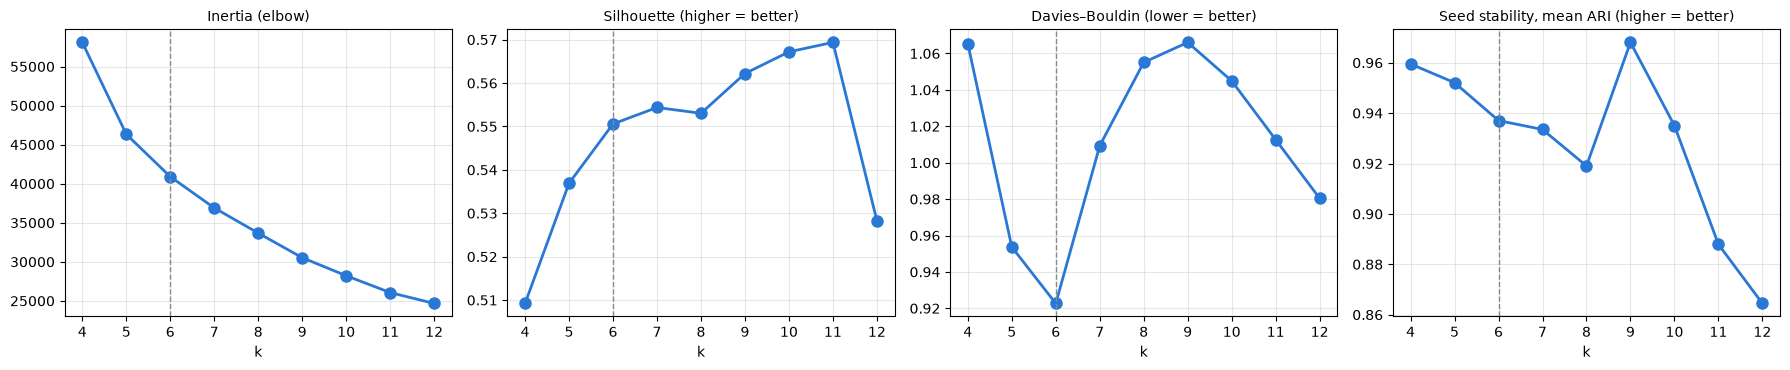

In [6]:
fig, axes = plt.subplots(1, 4, figsize=(18, 3.8))
for ax, (col, title) in zip(axes, [("inertia", "Inertia (elbow)"), ("silhouette", "Silhouette (higher = better)"),
                                   ("davies_bouldin", "Davies–Bouldin (lower = better)"),
                                   ("seed_ari_mean", "Seed stability, mean ARI (higher = better)")]):
    ax.plot(scores.index, scores[col], marker="o", color="#2a78d6", linewidth=2, markersize=8)
    ax.axvline(K, color="#888888", linestyle="--", linewidth=1)
    ax.set_title(title, fontsize=10)
    ax.set_xlabel("k")
    ax.grid(alpha=0.3)
plt.tight_layout()
fig.savefig(FIGURES / "06_choose_k.png", dpi=150, bbox_inches="tight")
plt.show()

**Choice: k = 6** (first run, 30 Oct 2026):
- **Seed stability is clearly best at k = 6** (mean ARI 0.95, worst pair 0.80). At k = 4–5 the result depends on the seed (worst pairs 0.41), so those clusterings are not robust.
- **Davies–Bouldin is lowest at k = 6** (0.95).
- Silhouette rises only slowly after k = 6 (0.49 → 0.51 at k = 9), and from k = 9 on the smallest cluster drops below 200 cells.
- 6 types are still easy to describe and to compare with the 10 urban LCZ classes.

If the indicators change, re-run and re-check this choice.

## 6. Profile the clusters
A cluster is not a type until we can describe it. For each cluster:
- **heatmap of mean z-scores:** how far above (red) or below (blue) the average cell each indicator is. This is what k-means "sees".
- **table of medians in original units:** what this means in real numbers (metres, shares, counts)
- **profiling-only variables** (not used for clustering): children and seniors share, NDVI, FAR, residential share. Age shares are computed from summed counts over the whole cluster, so tiny cells don't distort them.

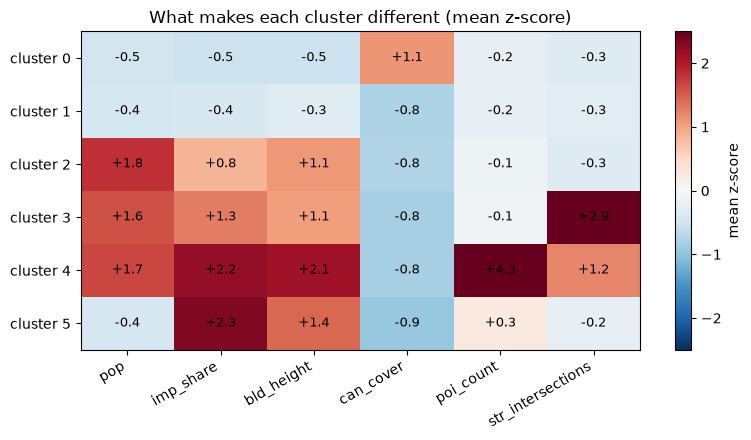

In [7]:
lab = pd.Series(labels[K], index=Z.index, name="cluster")

# Order clusters by mean imperviousness, so cluster 0 is the most natural and the last is the most built-up
order = Z.groupby(lab)["imp_share"].mean().sort_values().index
lab = lab.map({old: new for new, old in enumerate(order)})

zmean = Z.groupby(lab).mean()
fig, ax = plt.subplots(figsize=(8, 0.5 * K + 1.5))
im = ax.imshow(zmean, cmap="RdBu_r", vmin=-2.5, vmax=2.5, aspect="auto")
ax.set_xticks(range(len(FEATURES)), FEATURES, rotation=30, ha="right")
ax.set_yticks(range(K), [f"cluster {c}" for c in zmean.index])
for i in range(K):
    for j in range(len(FEATURES)):
        ax.text(j, i, f"{zmean.iloc[i, j]:+.1f}", ha="center", va="center", fontsize=9)
fig.colorbar(im, ax=ax, label="mean z-score")
ax.set_title("What makes each cluster different (mean z-score)")
plt.tight_layout()
fig.savefig(FIGURES / "06_profile_heatmap.png", dpi=150, bbox_inches="tight")
plt.show()

In [8]:
prof = data.loc[Z.index].assign(cluster=lab)
g = prof.groupby("cluster")

profile = pd.DataFrame({
    "cells": g.size(),
    "share_of_cells": (g.size() / len(prof)).round(3),
    "residents": g["pop"].sum().astype(int),
})
for col in FEATURES:
    profile[f"{col} (median)"] = g[col].median()

# Profiling only, NOT used for clustering
profile["children_0_14 %"] = 100 * g["pop_0_14"].sum() / g["pop"].sum()
profile["seniors_65+ %"] = 100 * g["pop_65plus"].sum() / g["pop"].sum()
profile["ndvi (median)"] = g["ndvi_mean"].median()
profile["far (median)"] = g["bld_far"].median()
profile["residential_share (median)"] = g["bld_residential_share"].median()
profile.round(2).T

cluster,0,1,2,3,4,5
cells,11412.000000,9145.000000,2611.00,2029.00,1044.00,1224.000000
share_of_cells,0.420000,0.330000,0.10,0.07,0.04,0.040000
residents,433.000000,1326.000000,131030.00,88501.00,78802.00,334.000000
pop (median),0.000000,0.000000,24.00,29.00,37.00,0.000000
imp_share (median),0.000000,0.000000,0.32,0.46,0.67,0.730000
bld_height (median),0.000000,0.000000,7.91,8.08,12.18,9.600000
can_cover (median),0.960000,0.080000,0.09,0.08,0.09,0.030000
poi_count (median),0.000000,0.000000,0.00,0.00,2.00,0.000000
str_intersections (median),0.000000,0.000000,0.00,1.00,1.00,0.000000
children_0_14 %,15.240000,10.710000,14.11,14.29,12.80,6.890000


## 7. Map
Grey = not clustered (outside the building data extent or water).

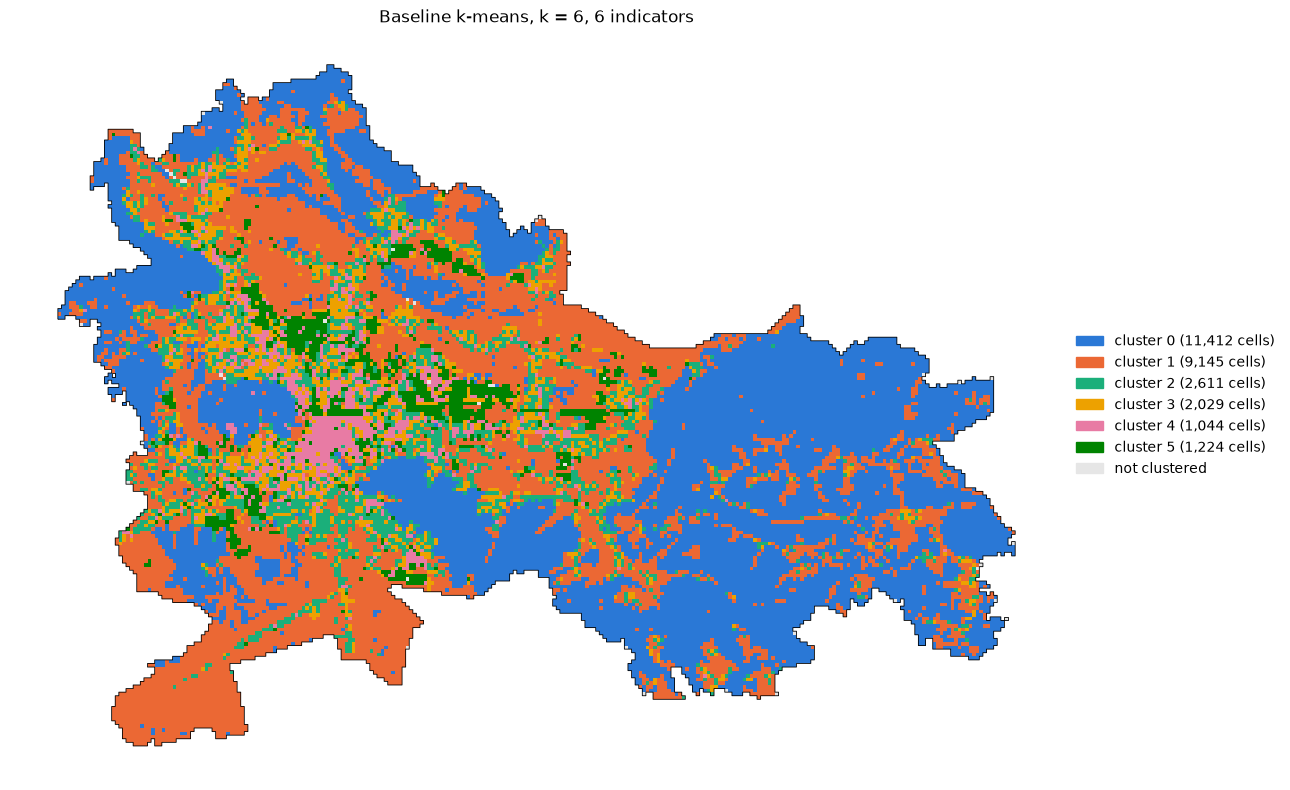

In [9]:
gdf = cells[["cell_id", "geometry"]].merge(lab.reset_index(), on="cell_id", how="left")
assert K <= len(CLUSTER_COLORS), "more clusters than colours: fold or facet instead"
cmap = ListedColormap(CLUSTER_COLORS[:K])

fig, ax = plt.subplots(figsize=(13, 10))
gdf[gdf["cluster"].isna()].plot(ax=ax, color="#e6e6e6", linewidth=0)
gdf.dropna(subset=["cluster"]).plot(ax=ax, column="cluster", cmap=cmap, vmin=-0.5, vmax=K - 0.5, linewidth=0)
cells.dissolve().boundary.plot(ax=ax, color="black", linewidth=0.6)
handles = [Patch(color=CLUSTER_COLORS[c], label=f"cluster {c} ({(lab == c).sum():,} cells)") for c in range(K)]
handles.append(Patch(color="#e6e6e6", label="not clustered"))
ax.legend(handles=handles, loc="center left", bbox_to_anchor=(1.0, 0.5), frameon=False)
ax.set_title(f"Baseline k-means, k = {K}, 6 indicators")
ax.set_axis_off()
plt.tight_layout()
fig.savefig(FIGURES / "06_baseline_map.png", dpi=150, bbox_inches="tight")
plt.show()

## 8. Save
One column per k, so later notebooks (stability, ablation, LST evaluation) can use any k without re-running.
Cluster numbers for `cluster` (the chosen k) are ordered by imperviousness; the `k4` … `k12` columns keep k-means' own numbering.

In [10]:
out = pd.DataFrame({f"k{k}": labels[k] for k in K_RANGE}, index=Z.index)
out.insert(0, "cluster", lab)
out.index.name = "cell_id"
out.to_csv(PROCESSED / "clusters_baseline.csv")
print(f"Saved {len(out):,} rows to {PROCESSED / 'clusters_baseline.csv'}")

Saved 27,465 rows to C:\Users\Maks\Desktop\Maks_šola\FRI\masters\urban-analysis\data\processed\clusters_baseline.csv


## Summary
First reading of the 6 clusters (first run, 30 Oct 2026). These are **clusters, not yet types**: names are tentative until they are checked on the map and tested.

| cluster | stands out by | tentative reading |
|---|---|---|
| 0 | trees (canopy 0.94), nothing built | forest and wooded hills (Rožnik, Golovec, edges) |
| 1 | nothing stands out; low trees, nothing built | open land: fields, meadows, Barje |
| 2 | residents, mid-height buildings, few intersections | residential, loosely connected streets |
| 3 | residents + many intersections | residential, dense street grid |
| 4 | very sealed, tall-ish, almost no residents, residential share 0 | non-residential built-up: industry, BTC, logistics |
| 5 | POI (z = +3.9), tallest buildings, sealed | centre and mixed-use: old town, main streets |

**What to look at next:**
- Clusters 2 and 3 differ almost only by `str_intersections`, which is 0 or 1 in most cells. At 100 m this is noisy ("salt and pepper" on the map). Counting intersections and POI within a radius (e.g. 300 m) instead of only inside the cell may give more coherent areas.
- Stability across feature subsets and k (ARI), spatial coherence (Moran's I).
- Held-out test: do these clusters differ in Landsat LST?

---
### Re-run on all of MOL (1 Nov 2026)
Building data now covers MOL (`02a`), so **27,465 cells** are clustered instead of 16,351 (300,426 of 300,443 residents). The numbers above the line are from the first run.
- Scores: k = 6 is no longer clearly the most seed-stable (mean ARI: k4 0.96, k5 0.95, **k6 0.94**, k9 0.97). Davies–Bouldin is still lowest at k = 6 (0.92). k = 6 kept for now.
- The same 6 clusters appear: forest (11,412 cells; now includes the forested hills in the east), open land (9,145), the two residential clusters split by in-cell intersections (2,611 / 2,029),
  centre/mixed and non-residential.
- **Cluster numbers changed:** centre/mixed is now **cluster 4** (1,044 cells, POI median 2) and non-residential is **cluster 5** (1,224 cells), because clusters are numbered by mean imperviousness.